<a href="https://colab.research.google.com/github/NeilMorales/Pranshu_Ranjan_eda/blob/main/Pranshu_Ranjan_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Loading the Dataset and Basic Statistical Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/PhDPublications.csv"
df = pd.read_csv(url)

print("--- Dataset Preview ---")
display(df.head())
print(f"\nShape: {df.shape}")
print("\n--- Basic Statistics ---")
display(df.describe(include='all'))

--- Dataset Preview ---


,rownames,articles,gender,married,kids,prestige,mentor
0,1,0,male,yes,0,2.52,7
1,2,0,female,no,0,2.05,6
2,3,0,female,no,0,3.75,6
3,4,0,male,yes,1,1.18,3
4,5,0,female,no,0,3.75,26



Shape: (915, 7)

--- Basic Statistics ---


,rownames,articles,gender,married,kids,prestige,mentor
count,915.000000,915.000000,915,915,915.000000,915.000000,915.000000
unique,NaN,NaN,2,2,NaN,NaN,NaN
top,NaN,NaN,male,yes,NaN,NaN,NaN
freq,NaN,NaN,494,606,NaN,NaN,NaN
mean,458.000000,1.692896,NaN,NaN,0.495082,3.103109,8.767213
std,264.282046,1.926069,NaN,NaN,0.764880,0.984249,9.483916
min,1.000000,0.000000,NaN,NaN,0.000000,0.755000,0.000000
25%,229.500000,0.000000,NaN,NaN,0.000000,2.260000,3.000000
50%,458.000000,1.000000,NaN,NaN,0.000000,3.150000,6.000000
75%,686.500000,2.000000,NaN,NaN,1.000000,3.920000,12.000000


### 2. Handling Missing Data

In [3]:
print("Missing values before:")
print(df.isnull().sum())

# Filling numeric with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Filling categorical with mode
for col in df.select_dtypes(exclude=np.number).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after handling:")
print(df.isnull().sum())

Missing values before:
rownames    0
articles    0
gender      0
married     0
kids        0
prestige    0
mentor      0
dtype: int64

Missing values after handling:
rownames    0
articles    0
gender      0
married     0
kids        0
prestige    0
mentor      0
dtype: int64


### 3. Data Cleaning

In [4]:
# Remove duplicates
duplicate_count = df.duplicated().sum()
df.drop_duplicates(inplace=True)

# Standardize column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

print(f"Removed {duplicate_count} duplicates.")
print("Cleaned columns:", df.columns.tolist())

Removed 0 duplicates.
Cleaned columns: ['rownames', 'articles', 'gender', 'married', 'kids', 'prestige', 'mentor']


### 4. Data Transformation

In [5]:
# Normalization of numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    min_val = df[col].min()
    max_val = df[col].max()
    if max_val != min_val:
        df[col] = (df[col] - min_val) / (max_val - min_val)

print("Data transformation (Min-Max scaling) applied to numeric columns.")
display(df.head())

Data transformation (Min-Max scaling) applied to numeric columns.


,rownames,articles,gender,married,kids,prestige,mentor
0,0.000000,0.0,male,yes,0.000000,0.456662,0.090909
1,0.001094,0.0,female,no,0.000000,0.335058,0.077922
2,0.002188,0.0,female,no,0.000000,0.774903,0.077922
3,0.003282,0.0,male,yes,0.333333,0.109961,0.038961
4,0.004376,0.0,female,no,0.000000,0.774903,0.337662


### 5. Univariate Analysis

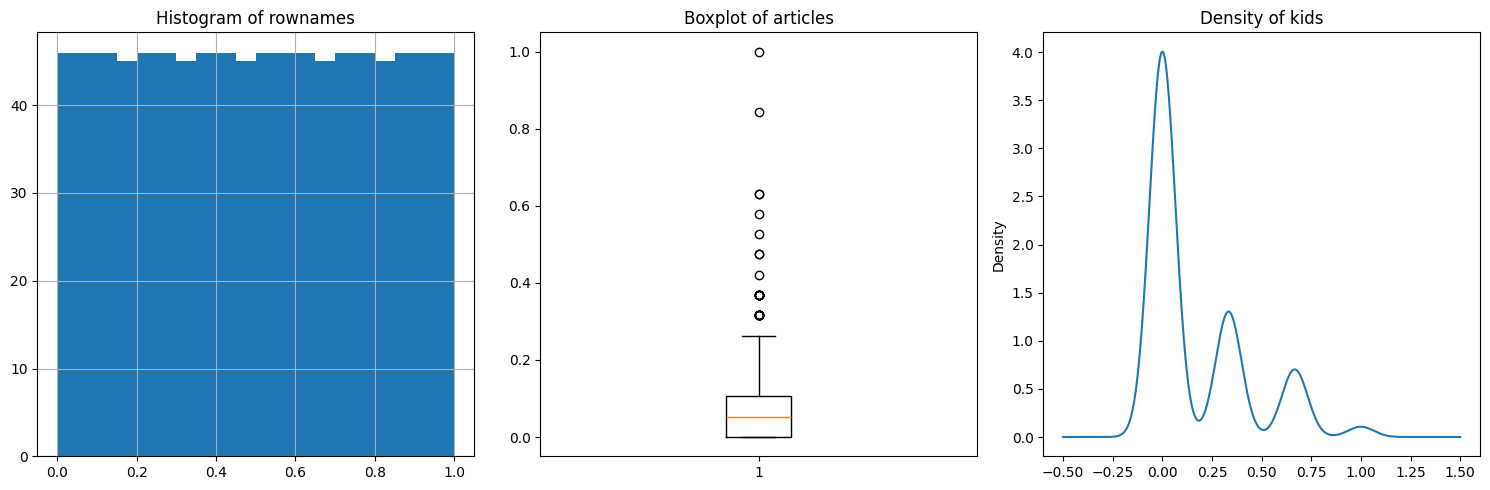

In [6]:
plt.figure(figsize=(15, 5))

# Visualization 1: Histogram
plt.subplot(1, 3, 1)
df[numeric_cols[0]].hist(bins=20)
plt.title(f"Histogram of {numeric_cols[0]}")

# Visualization 2: Boxplot
plt.subplot(1, 3, 2)
plt.boxplot(df[numeric_cols[1]])
plt.title(f"Boxplot of {numeric_cols[1]}")

# Visualization 3: Density Plot
plt.subplot(1, 3, 3)
df[numeric_cols[2]].plot(kind='density')
plt.title(f"Density of {numeric_cols[2]}")

plt.tight_layout()
plt.show()

### 6. Bivariate Analysis

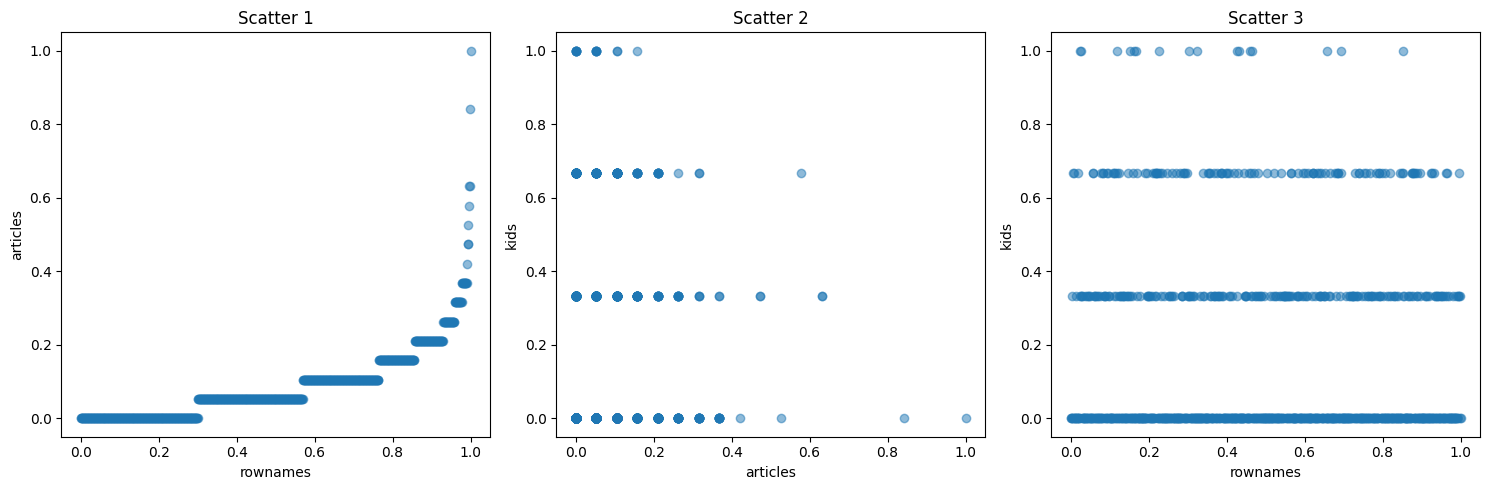

In [7]:
plt.figure(figsize=(15, 5))

# Viz 1
plt.subplot(1, 3, 1)
plt.scatter(df[numeric_cols[0]], df[numeric_cols[1]], alpha=0.5)
plt.xlabel(numeric_cols[0]); plt.ylabel(numeric_cols[1])
plt.title("Scatter 1")

# Viz 2
plt.subplot(1, 3, 2)
plt.scatter(df[numeric_cols[1]], df[numeric_cols[2]], alpha=0.5)
plt.xlabel(numeric_cols[1]); plt.ylabel(numeric_cols[2])
plt.title("Scatter 2")

# Viz 3
plt.subplot(1, 3, 3)
plt.scatter(df[numeric_cols[0]], df[numeric_cols[2]], alpha=0.5)
plt.xlabel(numeric_cols[0]); plt.ylabel(numeric_cols[2])
plt.title("Scatter 3")

plt.tight_layout()
plt.show()

### 7. Multivariate Analysis

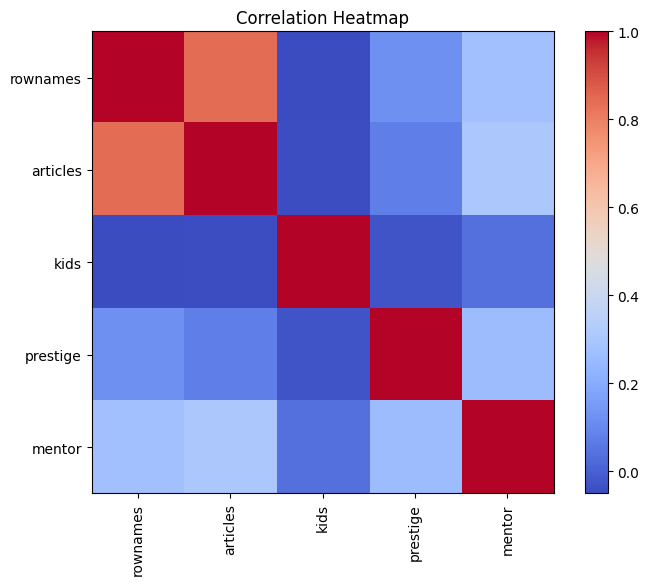

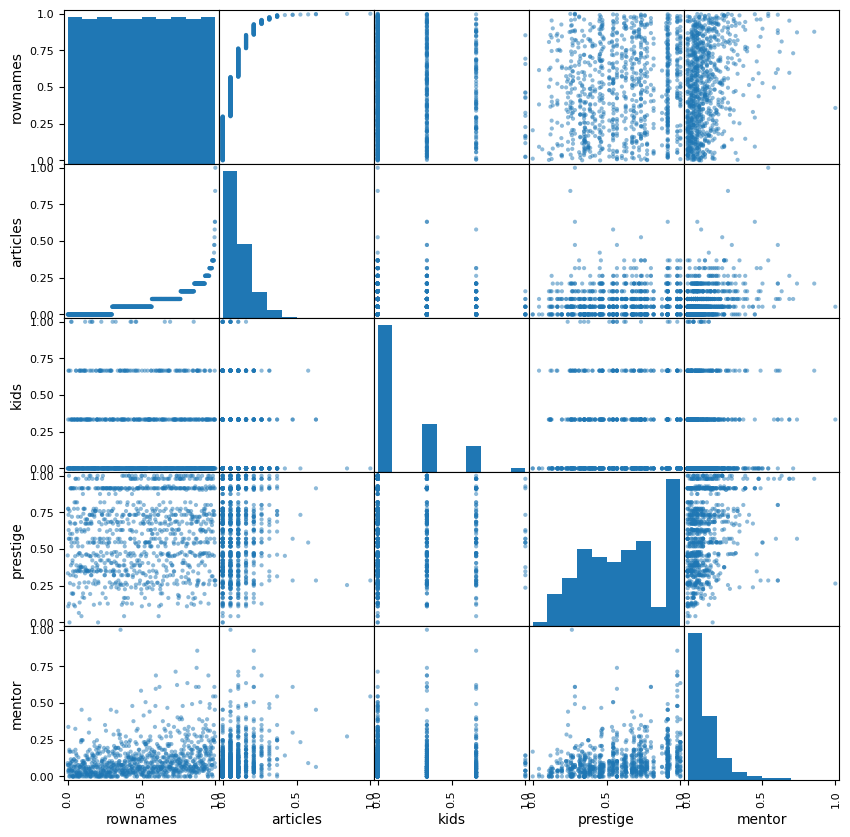

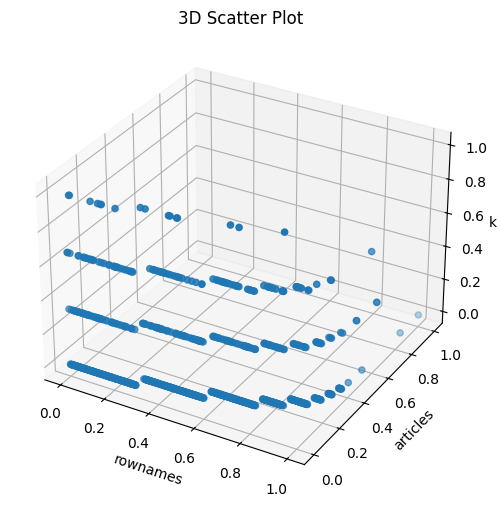

In [9]:
# Viz 1: Heatmap
corr = df[numeric_cols].corr()
plt.figure(figsize=(8,6))
plt.imshow(corr, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

# Viz 2: Scatter Matrix
pd.plotting.scatter_matrix(df[numeric_cols], figsize=(10,10))
plt.show()

# Viz 3: 3D Scatter
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df[numeric_cols[0]], df[numeric_cols[1]], df[numeric_cols[2]])
ax.set_xlabel(numeric_cols[0]); ax.set_ylabel(numeric_cols[1]); ax.set_zlabel(numeric_cols[2])
plt.title("3D Scatter Plot")
plt.show()